In [ ]:
!pip install kagglehub

## Downloading Dataset

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("pypiahmad/landslide4sense-challenge")

print("Path to dataset files:", path)

In [1]:
import pandas as pd 
import numpy as np
import h5py
import glob
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

I0000 00:00:1792983867.411692    7494 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792983867.421720    7494 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792983868.323864    7494 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792983869.846145    7494 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [5]:
!tree ..

..
├── app
│   ├── __init__.py
│   ├── main.py
│   ├── routes
│   │   ├── __init__.py
│   │   └── prediction.py
│   ├── services
│   │   └── __init__.py
│   ├── static
│   │   └── css
│   │       └── style.css
│   └── templates
│       └── index.html
├── data
│   ├── TestData
│   │   └── img
│   │       ├── image_100.h5
│   │       ├── image_101.h5
│   │       ├── image_102.h5
│   │       ├── image_103.h5
│   │       ├── image_104.h5
│   │       ├── image_105.h5
│   │       ├── image_106.h5
│   │       ├── image_107.h5
│   │       ├── image_108.h5
│   │       ├── image_109.h5
│   │       ├── image_10.h5
│   │       ├── image_110.h5
│   │       ├── image_111.h5
│   │       ├── image_112.h5
│   │       ├── image_113.h5
│   │       ├── image_114.h5
│   │       ├── image_115.h5
│   │       ├── image_116.h5
│   │       ├── image_117.h5
│   │       ├── image_118.h5
│   │       ├── image_119.h5
│   │       ├── image_11.h5
│   │       ├── image_120.h5
│   │       ├── image_121.h5
│   │       ├

In [21]:
root_dir = Path.cwd().parents[0]
print("Root directory:", root_dir)

Root directory: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-


In [6]:

sam_img = root_dir / "data" / "TrainData" /"img"/"image_3.h5"
sam_mask = root_dir / "data" / "TrainData" /"mask"/"mask_3.h5"
print("Path to sample image:", sam_img)
print("Path to sample mask:", sam_mask)
print("Path to sample image:", sam_img)

print("Image exists:", sam_img.exists())
print("Mask exists:", sam_mask.exists())

Path to sample image: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/data/TrainData/img/image_3.h5
Path to sample mask: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/data/TrainData/mask/mask_3.h5
Path to sample image: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/data/TrainData/img/image_3.h5
Image exists: True
Mask exists: True


In [17]:
with h5py.File(sam_img,'r') as f:
    print("Image keys: ", list(f.keys()))

    for key in f.keys():
        # print(f"Key: {np.str_(key)}")
        arr = f[key][:]
        print(f"Shape of {key}: {arr.shape}")
        print(f"Shape of {key}: {f[key].shape}")
        print(f"Data type of {key}: {f[key].dtype}")
        print(f"Min value of {key}: {np.min(arr)}")
        print(f"Max value of {key}: {np.max(arr)}")
        print(f"Mean value of {key}: {np.mean(arr)}")
with h5py.File(sam_mask,'r') as f:
    print("mask Keys: ", list(f.keys()))
    for key in f.keys():
        arr = f[key][:]
        print(f"Shape of {key}: {arr.shape}")
        print(f"Data type of {key}: {f[key].dtype}")
        print(f"Min value of {key}: {np.min(arr)}")
        print(f"Max value of {key}: {np.max(arr)}")
        print(f"Mean value of {key}: {np.mean(arr)}")

Image keys:  ['img']
Shape of img: (128, 128, 14)
Shape of img: (128, 128, 14)
Data type of img: float64
Min value of img: 0.0
Max value of img: 3.7064536467514286
Mean value of img: 1.2100381415591082
mask Keys:  ['mask']
Shape of mask: (128, 128)
Data type of mask: uint8
Min value of mask: 0
Max value of mask: 0
Mean value of mask: 0.0


In [ ]:
import h5py
import numpy as np

with h5py.File(sam_img, 'r') as f:
    for key in f.keys():
        arr = f[key][:]
        
        print(f"\n--- Raw data for {key} ---")
        
        # If it's a 2D grid (like a mask)
        # if len(arr.shape) == 2:
        #     print(arr) # Prints the first 5 rows and 5 columns
            
        # If it's a 3D grid (like an RGB image or multi-channel feature)
        if len(arr.shape) == 3:
            # Prints the first channel, first 5 rows, and 5 columns
            print(arr)
    


--- Raw data for img ---
[[[1.14048021 1.21508788 1.33400388 ... 1.33870874 1.42911473 1.06103343]
  [1.13958078 1.21144989 1.36113616 ... 1.33293844 1.33055509 1.05326977]
  [1.13958078 1.2078119  1.33098918 ... 1.24253713 0.98559636 1.05326977]
  ...
  [1.07572108 1.05016577 1.00389444 ... 0.35006464 2.02047255 1.2188945 ]
  [1.07572108 1.04895311 0.99786505 ... 0.30967257 2.11903218 1.21501267]
  [1.07572108 1.0622924  0.9903283  ... 0.30967257 2.168312   1.22277633]]

 [[1.14767567 1.22842717 1.40484928 ... 1.39833513 1.28127527 1.04291822]
  [1.1539717  1.20417391 1.37018025 ... 1.30601039 1.23199545 1.04550611]
  [1.1539717  1.20417391 1.34154062 ... 1.24446057 1.13343582 1.04680005]
  ...
  [1.07572108 1.0622924  1.02047528 ... 0.35006464 1.82335327 1.2279521 ]
  [1.07572108 1.07684435 1.03253408 ... 0.30967257 1.82335327 1.2370097 ]
  [1.07572108 1.05865441 1.01746059 ... 0.30967257 1.82335327 1.24606731]]

 [[1.14767567 1.23934113 1.40484928 ... 1.44642094 1.084156   1.036448

In [24]:

from pathlib import Path

root_dir = Path.cwd().parent
mask_dir = root_dir / "data" / "TrainData" / "mask"

print("Current directory:", Path.cwd())
print("Project root:", root_dir)
print("Mask directory:", mask_dir)
print("Directory exists:", mask_dir.is_dir())

# Count all entries, regardless of extension
if mask_dir.is_dir():
    entries = list(mask_dir.iterdir())
    print("Total entries:", len(entries))
    print("First 10 filenames:", [p.name for p in entries[:10]])

    # Count HDF5 files without relying on case-sensitive globbing
    h5_files = [
        p for p in entries
        if p.is_file() and p.suffix.lower() in (".h5", ".hdf5")
    ]
    print("HDF5 files found:", len(h5_files))


Current directory: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/notebooks
Project root: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-
Mask directory: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/data/TrainData/mask
Directory exists: True
Total entries: 3799
First 10 filenames: ['mask_273.h5', 'mask_2920.h5', 'mask_680.h5', 'mask_1215.h5', 'mask_3399.h5', 'mask_3761.h5', 'mask_2959.h5', 'mask_1880.h5', 'mask_1596.h5', 'mask_973.h5']
HDF5 files found: 3799


In [27]:

mask_dir = root_dir / "data" / "TrainData" / "mask"

mask_files = sorted(mask_dir.glob("*.h5"))

print("Total masks found:", len(mask_files))

total_pixels = 0
positive_pixels = 0
positive_masks = 0
label_counts = {}

for mask_path in mask_files[:100]:
    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:]

    total_pixels += mask.size
    positive_pixels += np.count_nonzero(mask > 0)
    positive_masks += int(np.any(mask > 0))

    values, counts = np.unique(mask, return_counts=True)
    for value, count in zip(values, counts):
        label_counts[int(value)] = (
            label_counts.get(int(value), 0) + int(count)
        )

print("Masks checked:", min(100, len(mask_files)))
print("Masks with positive pixels:", positive_masks)
print("Label counts:", label_counts)
print(
    "Positive pixel percentage:",
    100 * positive_pixels / total_pixels if total_pixels else 0
)


Total masks found: 3799
Masks checked: 100
Masks with positive pixels: 84
Label counts: {0: 1595754, 1: 42646}
Positive pixel percentage: 2.6029052734375


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.9861337078574212..4.829584218436117].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.9861337078574212..4.829584218436117].


Selected sample: 1
Image shape: (128, 128, 14)
Mask shape: (128, 128)
Mask values: (array([0, 1], dtype=uint8), array([15979,   405]))


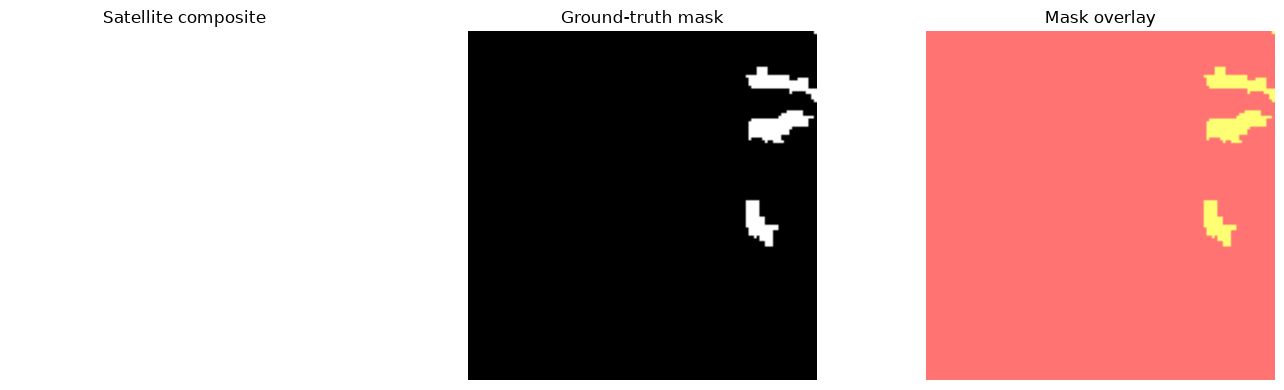

In [29]:


image_dir = root_dir / "data" / "TrainData" / "img"
mask_dir = root_dir / "data" / "TrainData" / "mask"

# Find a sample containing landslide pixels
selected_id = None

for mask_path in sorted(mask_dir.glob("mask_*.h5")):
    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:]

    if np.any(mask > 0):
        selected_id = mask_path.stem.replace("mask_", "")
        break

if selected_id is None:
    raise ValueError("No positive mask found.")

image_path = image_dir / f"image_{selected_id}.h5"

with h5py.File(image_path, "r") as f:
    image = f["img"][:]

with h5py.File(mask_dir / f"mask_{selected_id}.h5", "r") as f:
    mask = f["mask"][:]

print("Selected sample:", selected_id)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask, return_counts=True))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Display a three-band composite for inspection
axes[0].imshow(image[:, :, [3, 2, 1]])
axes[0].set_title("Satellite composite")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image[:, :, [3, 2, 1]])
axes[2].imshow(mask, cmap="autumn", alpha=0.55, vmin=0, vmax=1)
axes[2].set_title("Mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Loader

In [30]:
def load_sample(sample_id, image_dir, mask_dir):
    image_path = image_dir / f"image_{sample_id}.h5"
    mask_path = mask_dir / f"mask_{sample_id}.h5"

    if not image_path.exists() or not mask_path.exists():
        raise FileNotFoundError(
            f"Missing image or mask for sample {sample_id}"
        )

    with h5py.File(image_path, "r") as f:
        image = f["img"][:].astype(np.float32)

    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:].astype(np.float32)

    # Add the output-channel dimension for segmentation models
    mask = mask[..., np.newaxis]

    return image, mask


image, mask = load_sample("1", image_dir, mask_dir)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask values:", np.unique(mask))


Image shape: (128, 128, 14)
Image dtype: float32
Image range: 0.0 6.397335
Mask shape: (128, 128, 1)
Mask dtype: float32
Mask values: [0. 1.]


## Plotting 14 bands

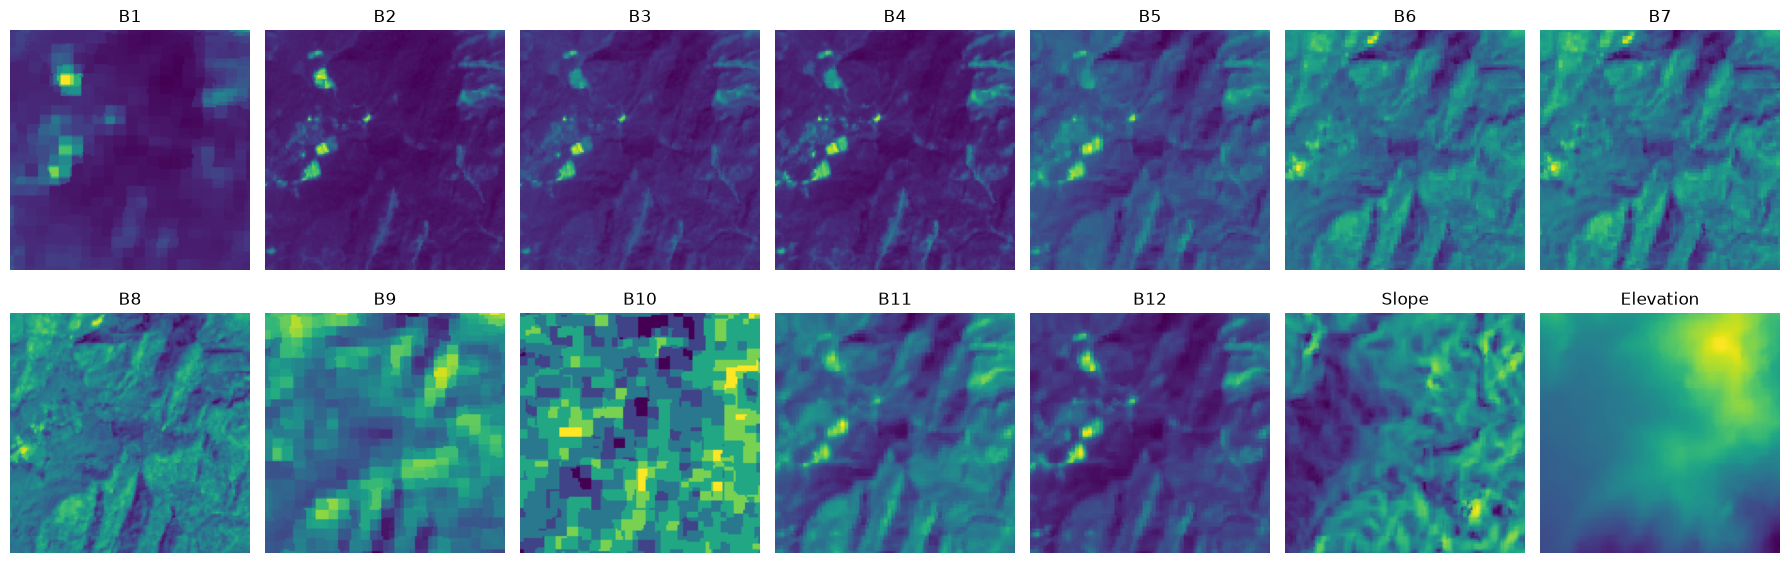

Per-channel statistics:
B1         | min=1.0955 | max=1.6783 | mean=1.1678 | std=0.0620
B2         | min=1.0744 | max=2.7382 | mean=1.2258 | std=0.1451
B3         | min=0.9979 | max=3.5393 | mean=1.3379 | std=0.2065
B4         | min=0.9861 | max=4.8296 | mean=1.4699 | std=0.3944
B5         | min=0.8810 | max=3.3630 | mean=1.5095 | std=0.2626
B6         | min=0.6887 | max=2.2614 | mean=1.2940 | std=0.1918
B7         | min=0.6590 | max=2.1689 | mean=1.2606 | std=0.1951
B8         | min=0.5491 | max=2.2711 | mean=1.2533 | std=0.2187
B9         | min=0.8471 | max=1.7416 | mean=1.2382 | std=0.1447
B10        | min=1.2158 | max=1.7684 | mean=1.4871 | std=0.1129
B11        | min=0.6535 | max=3.3169 | mean=1.5542 | std=0.3662
B12        | min=0.6155 | max=6.3973 | mean=1.7011 | std=0.6729
Slope      | min=0.0000 | max=3.6960 | mean=1.4253 | std=0.6460
Elevation  | min=0.8113 | max=1.7106 | mean=1.2556 | std=0.1702


In [31]:

channel_names = [
    "B1", "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B9", "B10", "B11", "B12",
    "Slope", "Elevation"
]

fig, axes = plt.subplots(2, 7, figsize=(18, 6))

for i, ax in enumerate(axes.flat):
    band = image[:, :, i]

    im = ax.imshow(band, cmap="viridis")
    ax.set_title(channel_names[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Per-channel statistics:")

for i, name in enumerate(channel_names):
    band = image[:, :, i]
    print(
        f"{name:10s} | "
        f"min={band.min():.4f} | "
        f"max={band.max():.4f} | "
        f"mean={band.mean():.4f} | "
        f"std={band.std():.4f}"
    )


In [33]:
channel_names = [
    "B1", "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B9", "B10", "B11", "B12",
    "Slope", "Elevation"
]

# Accumulate pixel statistics without loading all images at once.
channel_sum = np.zeros(14, dtype=np.float64)
channel_sum_sq = np.zeros(14, dtype=np.float64)
pixel_count = 0

## Processing IMages

In [34]:

image_files = sorted(image_dir.glob("image_*.h5"))

channel_sum = np.zeros(14, dtype=np.float64)
channel_sum_sq = np.zeros(14, dtype=np.float64)
pixel_count = 0

for i, image_path in enumerate(image_files):
    with h5py.File(image_path, "r") as f:
        image = f["img"][:].astype(np.float64)

    pixels = image.reshape(-1, 14)

    channel_sum += pixels.sum(axis=0)
    channel_sum_sq += np.square(pixels).sum(axis=0)
    pixel_count += pixels.shape[0]

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(image_files)} images")

channel_mean = channel_sum / pixel_count
channel_var = np.maximum(
    channel_sum_sq / pixel_count - channel_mean**2, 0
)
channel_std = np.sqrt(channel_var)

print("\nImages processed:", len(image_files))
print("\nChannel means:")
print(np.round(channel_mean, 6))

print("\nChannel standard deviations:")
print(np.round(channel_std, 6))


Processed 500/3799 images
Processed 1000/3799 images
Processed 1500/3799 images
Processed 2000/3799 images
Processed 2500/3799 images
Processed 3000/3799 images
Processed 3500/3799 images

Images processed: 3799

Channel means:
[0.925704 0.922701 0.954109 0.959639 1.02279  1.042612 1.035844 1.046756
 1.169941 1.173598 1.049497 1.037032 1.251108 1.649543]

Channel standard deviations:
[0.140988 0.220698 0.318425 0.572375 0.460096 0.446514 0.465075 0.494845
 0.513311 0.683558 0.532293 0.6628   0.678369 1.072711]


In [35]:

stats_path = root_dir / "models" / "normalization_stats.npz"
stats_path.parent.mkdir(parents=True, exist_ok=True)

np.savez(
    stats_path,
    mean=channel_mean,
    std=channel_std
)

print("Saved statistics to:", stats_path)


Saved statistics to: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/normalization_stats.npz


In [36]:

from pathlib import Path
import h5py
import numpy as np
import tensorflow as tf

root_dir = Path.cwd().parent

train_img_dir = root_dir / "data" / "TrainData" / "img"
train_mask_dir = root_dir / "data" / "TrainData" / "mask"
stats_path = root_dir / "models" / "normalization_stats.npz"

# Load per-channel statistics
stats = np.load(stats_path)
channel_mean = stats["mean"].astype(np.float32)
channel_std = stats["std"].astype(np.float32)

# Find image IDs and retain only IDs with both image and mask files
image_paths = sorted(train_img_dir.glob("image_*.h5"))
sample_ids = []

for image_path in image_paths:
    sample_id = image_path.stem.replace("image_", "")
    mask_path = train_mask_dir / f"mask_{sample_id}.h5"

    if mask_path.exists():
        sample_ids.append(sample_id)

print("Matched image-mask pairs:", len(sample_ids))


def load_sample_numpy(sample_id):
    # tf.numpy_function passes scalar byte strings
    if isinstance(sample_id, np.ndarray):
        sample_id = sample_id.item()
    if isinstance(sample_id, bytes):
        sample_id = sample_id.decode("utf-8")

    image_path = train_img_dir / f"image_{sample_id}.h5"
    mask_path = train_mask_dir / f"mask_{sample_id}.h5"

    with h5py.File(image_path, "r") as f:
        image = f["img"][:].astype(np.float32)

    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:].astype(np.float32)

    # Standardize each channel using training-set statistics
    image = (image - channel_mean) / np.maximum(channel_std, 1e-6)

    # U-Net expects (128, 128, 1) output masks
    mask = mask[..., np.newaxis]

    return image, mask


def load_sample_tf(sample_id):
    image, mask = tf.numpy_function(
        load_sample_numpy,
        [sample_id],
        [tf.float32, tf.float32]
    )

    image.set_shape((128, 128, 14))
    mask.set_shape((128, 128, 1))

    return image, mask


BATCH_SIZE = 16

train_ds = (
    tf.data.Dataset.from_tensor_slices(sample_ids)
    .shuffle(len(sample_ids), seed=42)
    .map(load_sample_tf, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Verify one batch
for batch_images, batch_masks in train_ds.take(1):
    print("Batch images:", batch_images.shape)
    print("Batch masks:", batch_masks.shape)
    print("Image dtype:", batch_images.dtype)
    print("Mask values:", tf.unique(tf.reshape(batch_masks, [-1]))[0].numpy())


Matched image-mask pairs: 3799
Batch images: (16, 128, 128, 14)
Batch masks: (16, 128, 128, 1)
Image dtype: <dtype: 'float32'>


E0000 00:00:1792989074.729561    7494 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Mask values: [0. 1.]


In [38]:
from sklearn.model_selection import train_test_split

root_dir = Path.cwd().parent
image_dir = root_dir / "data" / "TrainData" / "img"
mask_dir = root_dir / "data" / "TrainData" / "mask"

# Keep only samples with both image and mask files
sample_ids = sorted(
    p.stem.replace("image_", "")
    for p in image_dir.glob("image_*.h5")
    if (mask_dir / f"mask_{p.stem.replace('image_', '')}.h5").exists()
)

train_ids, val_ids = train_test_split(
    sample_ids,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Total labeled samples:", len(sample_ids))
print("Training samples:", len(train_ids))
print("Validation samples:", len(val_ids))
print("Overlap:", len(set(train_ids) & set(val_ids)))



Total labeled samples: 3799
Training samples: 3039
Validation samples: 760
Overlap: 0


In [39]:
BATCH_SIZE = 16

def load_sample_numpy(sample_id):
    if isinstance(sample_id, np.ndarray):
        sample_id = sample_id.item()
    if isinstance(sample_id, bytes):
        sample_id = sample_id.decode("utf-8")

    image_path = train_img_dir / f"image_{sample_id}.h5"
    mask_path = train_mask_dir / f"mask_{sample_id}.h5"

    with h5py.File(image_path, "r") as f:
        image = f["img"][:].astype(np.float32)

    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:].astype(np.float32)

    image = (image - channel_mean) / np.maximum(channel_std, 1e-6)
    mask = mask[..., np.newaxis]

    return image, mask


def load_sample_tf(sample_id):
    image, mask = tf.numpy_function(
        load_sample_numpy,
        [sample_id],
        [tf.float32, tf.float32]
    )
    image.set_shape((128, 128, 14))
    mask.set_shape((128, 128, 1))
    return image, mask


def create_dataset(ids, training=False):
    ds = tf.data.Dataset.from_tensor_slices(ids)

    if training:
        ds = ds.shuffle(
            buffer_size=len(ids),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_sample_tf, num_parallel_calls=2)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(1)

    return ds


train_ds = create_dataset(train_ids, training=True)
val_ds = create_dataset(val_ids, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

for images, masks in train_ds.take(1):
    print("Training batch:", images.shape, masks.shape)

for images, masks in val_ds.take(1):
    print("Validation batch:", images.shape, masks.shape)

Training batches: 190
Validation batches: 48
Training batch: (16, 128, 128, 14) (16, 128, 128, 1)
Validation batch: (16, 128, 128, 14) (16, 128, 128, 1)


In [40]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu",
        kernel_initializer="he_normal"
    )(x)
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu",
        kernel_initializer="he_normal"
    )(x)
    return x


def build_unet(input_shape=(128, 128, 14)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    b = conv_block(p4, 512)

    # Decoder
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding="same")(b)
    u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    # One probability per pixel
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c8)

    return Model(inputs, outputs, name="Landslide_UNet")


model = build_unet()
model.summary()


Model: "Landslide_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      4,064 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 256) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8, 512) │  1,180,160 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 512) │  2,359,808 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    524,544 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 512)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 7,763,265 (29.61 MB)

 Trainable params: 7,763,265 (29.61 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:

import tensorflow as tf

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_f * y_pred_f)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true_f) +
        tf.reduce_sum(y_pred_f) +
        smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)


def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


def iou_metric(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true > 0.5, tf.float32)
    y_pred = tf.cast(y_pred > 0.5, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection

    return (intersection + smooth) / (union + smooth)


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[
        dice_coefficient,
        iou_metric,
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

print("Model compiled successfully.")


Model compiled successfully.


In [42]:



model_dir = root_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "landslide_unet.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1,
    ),
]

print("Callbacks configured.")
print("Model destination:", model_dir / "landslide_unet.keras")


Callbacks configured.
Model destination: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras


## SmokeTest

In [43]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=callbacks,
)


Epoch 1/3


/home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 992ms/step - dice_coefficient: 0.3767 - iou_metric: 0.2851 - loss: 0.7384 - precision: 0.3326 - recall: 0.4429
Epoch 1: val_loss improved from None to 0.51249, saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras

Epoch 1: finished saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras
190/190 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step - dice_coefficient: 0.3767 - iou_metric: 0.2851 - loss: 0.7384 - precision: 0.3326 - recall: 0.4429 - val_dice_coefficient: 0.5716 - val_iou_metric: 0.4262 - val_loss: 0.5125 - val_precision: 0.7584 - val_recall: 0.5147 - learning_rate: 1.0000e-04
Epoch 2/3
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.6070 - iou_metric: 0.4662 - loss: 0.4561 - precision: 0.6436 - recall: 0.6568
Epoch 2: val_loss improved 

## With 50 Epoch

In [45]:

history_more = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks,
)


Epoch 1/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.6952 - iou_metric: 0.5571 - loss: 0.3544 - precision: 0.7260 - recall: 0.7312
Epoch 1: val_loss improved from 0.35618 to 0.33256, saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras

Epoch 1: finished saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras
190/190 ━━━━━━━━━━━━━━━━━━━━ 222s 1s/step - dice_coefficient: 0.6952 - iou_metric: 0.5571 - loss: 0.3544 - precision: 0.7260 - recall: 0.7312 - val_dice_coefficient: 0.7181 - val_iou_metric: 0.5836 - val_loss: 0.3326 - val_precision: 0.7626 - val_recall: 0.7306 - learning_rate: 1.0000e-04
Epoch 2/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.7007 - iou_metric: 0.5637 - loss: 0.3465 - precision: 0.7352 - recall: 0.7417
Epoch 2: val_lo

/tmp/ipykernel_7494/3482600502.py:13: RuntimeWarning: overflow encountered in cast
  image = f["img"][:].astype(np.float32)
/tmp/ipykernel_7494/3482600502.py:13: RuntimeWarning: invalid value encountered in cast
  image = f["img"][:].astype(np.float32)
/tmp/ipykernel_7494/3482600502.py:18: RuntimeWarning: overflow encountered in divide
  image = (image - channel_mean) / np.maximum(channel_std, 1e-6)


190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - dice_coefficient: nan - iou_metric: 0.2523 - loss: nan - precision: 0.7768 - recall: 0.3139
Epoch 9: val_loss did not improve from 0.32060
190/190 ━━━━━━━━━━━━━━━━━━━━ 1751s 9s/step - dice_coefficient: nan - iou_metric: 0.2523 - loss: nan - precision: 0.7768 - recall: 0.3139 - val_dice_coefficient: nan - val_iou_metric: 2.1956e-10 - val_loss: nan - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 10/50
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 933ms/step - dice_coefficient: nan - iou_metric: 2.1372e-10 - loss: nan - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 10: val_loss did not improve from 0.32060
190/190 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - dice_coefficient: nan - iou_metric: 2.1372e-10 - loss: nan - precision: 0.0000e+00 - recall: 0.0000e+00 - val_dice_coefficient: nan - val_iou_metric: 2.1956e-10 - val_loss: nan - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 11/50
190/1

## Finding Defective images 

In [48]:
import h5py
import numpy as np

image_files = sorted(train_img_dir.glob("image_*.h5"))

bad_images = []
float32_limit = np.finfo(np.float32).max

for path in image_files:
    try:
        with h5py.File(path, "r") as f:
            arr = f["img"][:]

        finite = np.isfinite(arr)
        finite_values = arr[finite]

        nonfinite_count = int(np.count_nonzero(~finite))
        too_large = (
            finite_values.size > 0
            and np.any(np.abs(finite_values) > float32_limit)
        )

        if nonfinite_count or too_large or finite_values.size == 0:
            bad_images.append({
                "file": path.name,
                "nonfinite": nonfinite_count,
                "too_large_for_float32": bool(too_large),
                "min": float(finite_values.min()) if finite_values.size else None,
                "max": float(finite_values.max()) if finite_values.size else None,
            })

    except Exception as e:
        bad_images.append({
            "file": path.name,
            "error": str(e),
        })

print("Images scanned:", len(image_files))
print("Problematic images:", len(bad_images))

for item in bad_images[:30]:
    print(item)

Images scanned: 3799
Problematic images: 14
{'file': 'image_2178.h5', 'nonfinite': 122, 'too_large_for_float32': True, 'min': -1.7730698668554611e+308, 'max': 2.248932623574708e+307}
{'file': 'image_2184.h5', 'nonfinite': 346, 'too_large_for_float32': True, 'min': -1.768706014804689e+308, 'max': 1.544892537873265e+308}
{'file': 'image_225.h5', 'nonfinite': 1843, 'too_large_for_float32': True, 'min': -1.7975054263704445e+308, 'max': 1.5840516580823493e+308}
{'file': 'image_2250.h5', 'nonfinite': 4352, 'too_large_for_float32': True, 'min': -1.797632380801144e+308, 'max': 1.5643230906894764e+308}
{'file': 'image_2251.h5', 'nonfinite': 2123, 'too_large_for_float32': True, 'min': -1.7976924028831754e+308, 'max': 1.7684653800333579e+308}
{'file': 'image_2252.h5', 'nonfinite': 1783, 'too_large_for_float32': True, 'min': -1.795594082998541e+308, 'max': 1.7359054206539182e+308}
{'file': 'image_2253.h5', 'nonfinite': 1850, 'too_large_for_float32': True, 'min': -1.7786631964315328e+308, 'max': 1.

In [49]:
import h5py
import numpy as np

bad_image_ids = [
    2178, 2184, 225, 2250, 2251, 2252, 2253,
    2254, 2255, 2256, 2257, 2462, 2463, 2464
]

for image_id in bad_image_ids:
    img_path = train_img_dir / f"image_{image_id}.h5"
    mask_path = root_dir / "data" / "TrainData" / "mask" / f"mask_{image_id}.h5"

    with h5py.File(img_path, "r") as f:
        img = f["img"][:]

    finite = np.isfinite(img)
    finite_values = img[finite]

    print(f"\nImage {image_id}")
    print("Shape:", img.shape)
    print("Non-finite:", np.count_nonzero(~finite))
    print("Finite min/max:", (
        (float(finite_values.min()), float(finite_values.max()))
        if finite_values.size else "No finite values"
    ))

    if mask_path.exists():
        with h5py.File(mask_path, "r") as f:
            mask = f["mask"][:]
        print("Mask values:", np.unique(mask, return_counts=True))
    else:
        print("Mask file missing:", mask_path.name)


Image 2178
Shape: (128, 128, 14)
Non-finite: 122
Finite min/max: (-1.7730698668554611e+308, 2.248932623574708e+307)
Mask values: (array([0, 1], dtype=uint8), array([16305,    79]))

Image 2184
Shape: (128, 128, 14)
Non-finite: 346
Finite min/max: (-1.768706014804689e+308, 1.544892537873265e+308)
Mask values: (array([0, 1], dtype=uint8), array([16056,   328]))

Image 225
Shape: (128, 128, 14)
Non-finite: 1843
Finite min/max: (-1.7975054263704445e+308, 1.5840516580823493e+308)
Mask values: (array([0, 1], dtype=uint8), array([15071,  1313]))

Image 2250
Shape: (128, 128, 14)
Non-finite: 4352
Finite min/max: (-1.797632380801144e+308, 1.5643230906894764e+308)
Mask values: (array([0], dtype=uint8), array([16384]))

Image 2251
Shape: (128, 128, 14)
Non-finite: 2123
Finite min/max: (-1.7976924028831754e+308, 1.7684653800333579e+308)
Mask values: (array([0], dtype=uint8), array([16384]))

Image 2252
Shape: (128, 128, 14)
Non-finite: 1783
Finite min/max: (-1.795594082998541e+308, 1.735905420653

In [50]:

import h5py
import numpy as np

for image_id in bad_image_ids:
    path = train_img_dir / f"image_{image_id}.h5"

    with h5py.File(path, "r") as f:
        img = f["img"][:]

    print(f"\n{'=' * 55}\nImage {image_id}")

    for ch in range(img.shape[-1]):
        values = img[:, :, ch]
        finite = np.isfinite(values)
        valid = values[finite]

        if valid.size == 0:
            print(f"Channel {ch:02d}: NO FINITE VALUES")
            continue

        vmin = float(valid.min())
        vmax = float(valid.max())
        invalid_count = int(np.count_nonzero(~finite))
        extreme_count = int(np.count_nonzero(
            finite & (np.abs(values) > 1e10)
        ))

        if invalid_count or extreme_count:
            print(
                f"Channel {ch:02d}: "
                f"invalid={invalid_count}, "
                f"extreme={extreme_count}, "
                f"min={vmin:.4e}, max={vmax:.4e}"
            )



Image 2178
Channel 00: invalid=5, extreme=96, min=-1.6365e+308, max=6.8577e+303
Channel 01: invalid=8, extreme=95, min=-1.6365e+308, max=5.5557e+277
Channel 02: invalid=8, extreme=89, min=-1.6365e+308, max=1.9491e+289
Channel 03: invalid=8, extreme=96, min=-1.6365e+308, max=5.6768e+277
Channel 04: invalid=11, extreme=95, min=-1.6365e+308, max=5.7412e+302
Channel 05: invalid=11, extreme=98, min=-1.6376e+308, max=2.2489e+307
Channel 06: invalid=10, extreme=90, min=-1.6381e+308, max=2.2489e+307
Channel 07: invalid=6, extreme=89, min=-1.6382e+308, max=2.2471e+307
Channel 08: invalid=17, extreme=83, min=-1.6337e+308, max=5.5719e+298
Channel 09: invalid=7, extreme=85, min=-1.7714e+308, max=5.0422e+277
Channel 10: invalid=12, extreme=68, min=-1.7731e+308, max=1.3461e+289
Channel 11: invalid=7, extreme=96, min=-1.6564e+308, max=5.0790e+277
Channel 12: invalid=6, extreme=97, min=-1.6376e+308, max=6.1720e+303
Channel 13: invalid=6, extreme=98, min=-1.6376e+308, max=4.3294e+288

Image 2184
Chann

## removing bad images 

In [51]:

import numpy as np

bad_image_ids = {
    2178, 2184, 225, 2250, 2251, 2252, 2253,
    2254, 2255, 2256, 2257, 2462, 2463, 2464
}

# Preserve the original split and filter out corrupted pairs.
train_ids_clean = [
    image_id for image_id in train_ids
    if int(image_id) not in bad_image_ids
]

val_ids_clean = [
    image_id for image_id in val_ids
    if int(image_id) not in bad_image_ids
]

print("Original training samples:", len(train_ids))
print("Clean training samples:", len(train_ids_clean))
print("Original validation samples:", len(val_ids))
print("Clean validation samples:", len(val_ids_clean))

print(
    "Corrupted samples removed from training:",
    len(train_ids) - len(train_ids_clean)
)
print(
    "Corrupted samples removed from validation:",
    len(val_ids) - len(val_ids_clean)
)


Original training samples: 3039
Clean training samples: 3028
Original validation samples: 760
Clean validation samples: 757
Corrupted samples removed from training: 11
Corrupted samples removed from validation: 3


# Rebuild the datasets

In [52]:

for images, masks in train_ds.take(1):
    print("Images:", images.shape)
    print("Masks:", masks.shape)
    print("All image values finite:", np.isfinite(images.numpy()).all())
    print("All mask values finite:", np.isfinite(masks.numpy()).all())


Images: (16, 128, 128, 14)
Masks: (16, 128, 128, 1)
All image values finite: True
All mask values finite: True


In [53]:

import tensorflow as tf
from pathlib import Path

root_dir = Path.cwd().parent
model_path = root_dir / "models" / "landslide_unet.keras"

best_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "combined_loss": combined_loss,
        "dice_coefficient": dice_coefficient,
        "dice_loss": dice_loss,
        "iou_metric": iou_metric,
    },
)

print("Loaded checkpoint:", model_path)
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)
print("Learning rate:", float(
    tf.keras.backend.get_value(best_model.optimizer.learning_rate)
))


Loaded checkpoint: /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet.keras
Input shape: (None, 128, 128, 14)
Output shape: (None, 128, 128, 1)
Learning rate: 9.999999747378752e-05


In [54]:
callbacks[0] = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(root_dir / "models" / "landslide_unet_clean.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

In [55]:
history_clean = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
)

Epoch 1/10


/tmp/ipykernel_7494/3482600502.py:13: RuntimeWarning: overflow encountered in cast
  image = f["img"][:].astype(np.float32)


 22/190 ━━━━━━━━━━━━━━━━━━━━ 2:33 916ms/step - dice_coefficient: 0.0572 - iou_metric: 0.0281 - loss: 1.0484 - precision: 0.7272 - recall: 0.0288

/tmp/ipykernel_7494/3482600502.py:13: RuntimeWarning: invalid value encountered in cast
  image = f["img"][:].astype(np.float32)
/tmp/ipykernel_7494/3482600502.py:18: RuntimeWarning: overflow encountered in divide
  image = (image - channel_mean) / np.maximum(channel_std, 1e-6)


190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - dice_coefficient: 0.0296 - iou_metric: 0.0033 - loss: 1.0828 - precision: 0.7272 - recall: 0.0031

KeyboardInterrupt: 

In [56]:
bad_image_ids = {
    2178, 2184, 225, 2250, 2251, 2252, 2253,
    2254, 2255, 2256, 2257, 2462, 2463, 2464
}

print("Bad IDs in cleaned training split:",
      set(map(int, train_ids_clean)) & bad_image_ids)

print("Bad IDs in cleaned validation split:",
      set(map(int, val_ids_clean)) & bad_image_ids)

print("Training IDs:", len(train_ids_clean))
print("Validation IDs:", len(val_ids_clean))

Bad IDs in cleaned training split: set()
Bad IDs in cleaned validation split: set()
Training IDs: 3028
Validation IDs: 757


In [57]:
image = f["img"][:].astype(np.float32)

KeyError: 'Unable to synchronously open object (invalid identifier type to function)'

In [58]:
import h5py
import numpy as np

bad_after_cleaning = []

for image_id in train_ids_clean:
    path = train_img_dir / f"image_{int(image_id)}.h5"

    with h5py.File(path, "r") as f:
        image = f["img"][:]

    if (
        not np.isfinite(image).all()
        or np.any(np.abs(image[np.isfinite(image)]) >
                  np.finfo(np.float32).max)
    ):
        bad_after_cleaning.append(int(image_id))

print("Remaining problematic training images:",
      len(bad_after_cleaning))
print("IDs:", bad_after_cleaning[:50])

Remaining problematic training images: 0
IDs: []


In [59]:

from pathlib import Path
import h5py
import numpy as np
import tensorflow as tf

root_dir = Path.cwd().parent

train_img_dir = root_dir / "data" / "TrainData" / "img"
train_mask_dir = root_dir / "data" / "TrainData" / "mask"
stats_path = root_dir / "models" / "normalization_stats.npz"

stats = np.load(stats_path)
channel_mean = stats["mean"].astype(np.float32)
channel_std = stats["std"].astype(np.float32)

bad_image_ids = {
    2178, 2184, 225, 2250, 2251, 2252, 2253,
    2254, 2255, 2256, 2257, 2462, 2463, 2464
}

# Preserve the previously created cleaned split.
train_ids_clean = [
    str(int(i)) for i in train_ids
    if int(i) not in bad_image_ids
]
val_ids_clean = [
    str(int(i)) for i in val_ids
    if int(i) not in bad_image_ids
]

def load_sample_numpy(sample_id):
    if isinstance(sample_id, np.ndarray):
        sample_id = sample_id.item()
    if isinstance(sample_id, bytes):
        sample_id = sample_id.decode("utf-8")
    sample_id = str(sample_id)

    image_path = train_img_dir / f"image_{sample_id}.h5"
    mask_path = train_mask_dir / f"mask_{sample_id}.h5"

    with h5py.File(image_path, "r") as f:
        raw_image = f["img"][:]

    # Validate before float32 conversion.
    if not np.isfinite(raw_image).all():
        raise ValueError(f"Non-finite values in {image_path.name}")

    if np.any(np.abs(raw_image) > np.finfo(np.float32).max):
        raise ValueError(f"Float32 overflow risk in {image_path.name}")

    image = raw_image.astype(np.float32)

    with h5py.File(mask_path, "r") as f:
        mask = f["mask"][:].astype(np.float32)

    image = (image - channel_mean) / np.maximum(channel_std, 1e-6)

    if not np.isfinite(image).all():
        raise ValueError(f"Non-finite normalized image: {image_path.name}")

    mask = mask[..., np.newaxis]
    return image, mask

def load_sample_tf(sample_id):
    image, mask = tf.numpy_function(
        load_sample_numpy,
        [sample_id],
        [tf.float32, tf.float32]
    )
    image.set_shape((128, 128, 14))
    mask.set_shape((128, 128, 1))
    return image, mask

BATCH_SIZE = 16

def make_dataset(ids, training=False):
    ds = tf.data.Dataset.from_tensor_slices(ids)
    if training:
        ds = ds.shuffle(len(ids), seed=42)
    return (
        ds.map(load_sample_tf, num_parallel_calls=2)
          .batch(BATCH_SIZE)
          .prefetch(1)
    )

train_ds = make_dataset(train_ids_clean, training=True)
val_ds = make_dataset(val_ids_clean)

print("Training samples:", len(train_ids_clean))
print("Validation samples:", len(val_ids_clean))


Training samples: 3028
Validation samples: 757


In [60]:

for name, dataset in [("Training", train_ds), ("Validation", val_ds)]:
    for images, masks in dataset.take(1):
        image_values = images.numpy()
        mask_values = masks.numpy()

        print(f"\n{name}")
        print("Image shape:", image_values.shape)
        print("Mask shape:", mask_values.shape)
        print("Images finite:", np.isfinite(image_values).all())
        print("Masks finite:", np.isfinite(mask_values).all())
        print("Image min/max:", image_values.min(), image_values.max())



Training
Image shape: (16, 128, 128, 14)
Mask shape: (16, 128, 128, 1)
Images finite: True
Masks finite: True
Image min/max: -2.1063795 13.51203

Validation
Image shape: (16, 128, 128, 14)
Mask shape: (16, 128, 128, 1)
Images finite: True
Masks finite: True
Image min/max: -2.0797915 14.8547


In [61]:
clean_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(root_dir / "models" / "landslide_unet_clean.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

In [62]:
history_clean = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=clean_callbacks,
)

Epoch 1/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 981ms/step - dice_coefficient: 0.0255 - iou_metric: 2.3428e-10 - loss: 1.0866 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 1: val_loss improved from None to 1.09134, saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet_clean.keras

Epoch 1: finished saving model to /home/ovi/Desktop/Projects/Landslide-Detection/Landslide-Detection-by-satellite-image-processing-with-Deep-learning-/models/landslide_unet_clean.keras
190/190 ━━━━━━━━━━━━━━━━━━━━ 204s 1s/step - dice_coefficient: 0.0255 - iou_metric: 2.3428e-10 - loss: 1.0866 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_dice_coefficient: 0.0303 - val_iou_metric: 2.2315e-10 - val_loss: 1.0913 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - dice_coefficient: 0.0257 - iou_metric: 2.3148e-10 - loss: 1.0861 